1. Define a Pytorch Dataset and Dataloaders.  

In [51]:
# TODO: Enter your code here

from torch.utils.data import DataLoader
from common_utils import AudioDataset

weight_decay = 0.01
max_epoch = 100
batch_size = 128
patience = 5
initial_lr = 0.001

# may not use the conversion in AudioDataset, must convert to tensor manually due to audiodataset handling tensors and dataframes but not numpy arrays given by other methods in common utils
train_load = DataLoader(AudioDataset(nd_train,
    torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)
test_load = DataLoader(AudioDataset(nd_test,
    torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)


2. Next, define the model, optimizer and loss function.

In [52]:
# TODO: Enter your code here

from typing import Tuple 

def setup(
    first_layer_size: int = 256,
    adam_init_lr: float = initial_lr
) -> Tuple[MLP, nn.Module, torch.optim.Optimizer]:
    """
    Initializes the model, loss function, and optimizer for training.

    Args:
        first_layer_size (int, optional): 
            The number of neurons in the first hidden layer. Defaults to 256.
        adam_init_lr (float, optional): 
            The initial learning rate for the Adam optimizer. Defaults to the global variable `initial_lr`.

    Returns:
        Tuple[nn.Module, nn.Module, torch.optim.Optimizer]:
            - **model** (`nn.Module`): The initialized MLP model.  
            - **loss_fn** (`nn.Module`): The loss function used for binary classification (BCELoss).  
            - **optimizer** (`torch.optim.Optimizer`): The Adam optimizer configured with weight decay and learning rate.
    """
    model = MLP(hidden_sizes= [first_layer_size, 128, 64, 32])
    loss_fn = nn.BCELoss() # Suited for Final layer = perceptron
    optimizer = torch.optim.Adam(model.parameters(), weight_decay=weight_decay, lr = adam_init_lr)
    return model, loss_fn, optimizer

model, loss_fn, optimizer = setup()

3. Train model for 100 epochs. Record down train and test accuracies. Implement early stopping.

In [54]:
# TODO: Enter your code here

from common_utils import EarlyStopper
from typing import Optional

def train_loop(
    dataloader,
    model,
    loss_fn,
    optimizer
) -> Tuple[float, int, torch.Tensor]:
    train_loss= 0
    err = 0
    pred_p: Optional[torch.Tensor] = None
    for _batch, (X, Y) in enumerate(dataloader):
        pred = model(X)
        loss = loss_fn(pred, Y)

        pred_p = (pred > 0.5).int()
        err += (pred_p != Y).sum().item()

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    # pred p is returned because AUC score inherently relies on pairwise data, and cannot be calculated from other aggregate statistics
    # p = 0 <-> class blues
    # p = 1 <-> class metal
    assert pred_p is not None, "pred_p was never assigned!"
    return train_loss, err, pred_p

def test_loop(
    dataloader,
    model,
    loss_fn
) -> Tuple[float, int, torch.Tensor]:
    model.eval()
    with torch.no_grad():
        pred_p: Optional[torch.Tensor] = None
        test_loss = 0
        err = 0
        for X, Y in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, Y).item()
            pred_p = (pred > 0.5).int()
            err += (pred_p != Y).sum().item()
    model.train()
    assert pred_p is not None, "pred_p was never assigned!"
    return test_loss, err, pred_p

def train_and_test(
    train_load: DataLoader,
    test_load: DataLoader,
    model: MLP,
    loss_fn: nn.Module,
    optimizer: torch.optim.Optimizer,
    max_epoch: int = max_epoch,
    patience: int = patience
) -> Tuple[
    np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray,
    torch.Tensor, torch.Tensor
]:
    """
    Trains a PyTorch model and evaluates it on a test set with early stopping.

    The function performs epoch-by-epoch training and validation, tracking
    losses, errors, and accuracies. Training stops early if the validation loss
    fails to improve for a number of epochs specified by ``patience``.

    Args:
        train_load (DataLoader): DataLoader providing batches of training data.
        test_load (DataLoader): DataLoader providing batches of testing data.
        model (MLP): The PyTorch neural network model to train.
        loss_fn (nn.Module): Loss function used for optimization (e.g., BCELoss).
        optimizer (torch.optim.Optimizer): Optimizer instance (e.g., Adam).
        max_epoch (int, optional): Maximum number of training epochs.
            Defaults to the global variable ``max_epoch``.
        patience (int, optional): Number of epochs with no improvement in the
            validation loss before early stopping. Defaults to the global
            variable ``patience``.

    Returns:
        Tuple[
            np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray,
            torch.Tensor, torch.Tensor
        ]:
            A tuple containing:

            - **train_losses** (`np.ndarray`): Array of training loss values per epoch.  
            - **test_losses** (`np.ndarray`): Array of testing loss values per epoch.  
            - **epochs** (`np.ndarray`): Array of epoch indices completed.  
            - **train_acc_arr** (`np.ndarray`): Training accuracies per epoch.  
            - **test_acc_arr** (`np.ndarray`): Testing accuracies per epoch.  
            - **train_pred_probs** (`torch.Tensor`): Model predictions on the training set.  
            - **test_pred_probs** (`torch.Tensor`): Model predictions on the test set.  

    Notes:
        The predicted probabilities are returned because metrics such as ROC-AUC require
        access to the full set of pairwise predictions, which cannot be derived
        from aggregate statistics like accuracy or loss alone.
    """

    early_stopper = EarlyStopper(patience = patience)
    train_losses = []
    test_losses = []
    epochs = []

    # to calculate classification error
    train_err_arr = []
    test_err_arr = []

    train_pred_probs = []
    test_pred_probs = []
    
    for epoch in range(max_epoch):
        train_loss, train_err, train_pred_prob= train_loop(train_load, model, loss_fn, optimizer)
        test_loss, test_err, test_pred_prob = test_loop(test_load, model, loss_fn)

        train_losses.append(train_loss)
        test_losses.append(test_loss)
        train_err_arr.append(train_err)
        test_err_arr.append(test_err)
        epochs.append(epoch)
        train_pred_probs.append(train_pred_prob.detach().cpu())
        test_pred_probs.append(test_pred_prob.detach().cpu())

        if early_stopper.early_stop(test_loss):
            break
    
    train_pred_probs = torch.cat(train_pred_probs, dim=0)
    test_pred_probs = torch.cat(test_pred_probs, dim=0)

    train_acc_arr = np.ones(epochs[-1] + 1) - (np.array(train_err_arr) / train_size)
    test_acc_arr = np.ones(epochs[-1] + 1) - (np.array(test_err_arr) / test_size)
    # pred labels is returned because AUC score inherently relies on pairwise data, and cannot be calculated from other aggregate statistics
    return np.array(train_losses), np.array(test_losses), np.array(epochs), train_acc_arr, test_acc_arr, train_pred_probs, test_pred_probs

train_losses, test_losses, epochs, train_acc_arr, test_acc_arr, train_pred_probs, test_pred_probs = train_and_test(train_load, test_load, model, loss_fn, optimizer)

print(train_acc_arr)
print(test_acc_arr)

[0.60133333 0.81733333 0.862      0.90533333 0.948      0.964
 0.97333333 0.97733333 0.97933333 0.98466667 0.988      0.99
 0.99333333 0.994      0.99333333 0.99466667 0.992      0.99533333
 0.996      0.994      0.99666667 0.99533333 0.99666667 0.99533333
 0.998      0.99733333 0.998      0.99733333 0.99666667 0.99733333
 0.99733333]
[0.78  0.858 0.884 0.944 0.95  0.96  0.97  0.968 0.976 0.978 0.978 0.99
 0.984 0.986 0.98  0.98  0.984 0.988 0.978 0.986 0.988 0.988 0.988 0.986
 0.988 0.99  0.99  0.984 0.988 0.988 0.986]


> Plot train and test accuracies and losses on training and test data against training epochs and comment on the line plots.

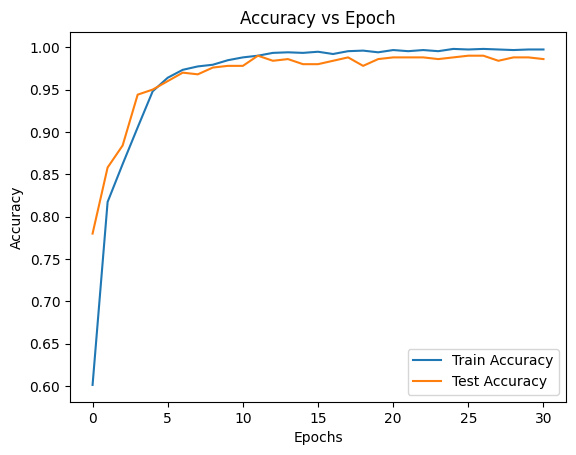

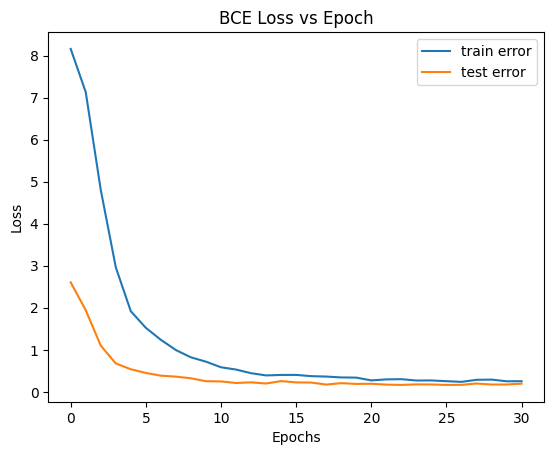

In [55]:
# TODO: Enter your code here

import matplotlib.pyplot as plt 
import numpy as np

plt.figure(0)
plt.plot(epochs, train_acc_arr, label= "Train Accuracy")
plt.plot(epochs, test_acc_arr, label= "Test Accuracy")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.figure(1)
plt.plot(epochs, train_losses, label= "train error")
plt.plot(epochs, test_losses, label= "test error")
plt.title("BCE Loss vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

\# TODO: \<Enter your answer here\>

Part A, Q2 (10 marks)
---

In this question, we will determine the optimal learning rate for the Adam optimizer. Find the optimal learning rate by training the neural network and evaluating the performances for different learning rates. Note: Use 5-fold cross-validation on training partition to perform hyperparameter selection. You will have to reconsider the scaling of the dataset during the 5-fold cross validation.

To reduce repeated code, you may need to place the network (MLP defined in QA1) in a separate file called **common_utils.py**. Import it here for Q2. You will not be repenalised for any error in QA1 here as the code in QA1 will not be remarked. The following code cell will not be marked.

In [56]:
# TODO: Enter your code here
import common_utils

>Plot mean cross-validation accuracies and mean cross-validation AUC scores on the final epoch for different learning rates as scatter plots. Limit search space to learning rates {0.0001, 0.0005, 0.001, 0.005, 0.01}. Keep batch_size fixed at 128. Create a table of time taken to train the network on the last epoch against different learning rates. Generate a confusion matrix for the optimal learning rate configuration. Finally, select the optimal learning rate and state a reason for your selection.

1. Define different folds for different learning rates to get a dictionary of training and validation datasets. Preprocess your datasets accordingly. Please use the following name conventions:
    - X_train_scaled_dict[learning_rate] is a list of the preprocessed training matrix for the different folds. 
    - X_val_scaled_dict[learning_rate] is a list of the processed validation matrix for the different folds. 
    - y_train_dict[learning_rate] and y_val_dict[learning_rate] is a list of labels for the different folds.

In [57]:
# TODO: Enter your code here

lr_tuple = (0.0001, 0.0005, 0.001, 0.005, 0.01)
batch_size = 128

# may not use split_dataset, preprocess_dataset from common_utils due to them fixing the test and something datasets
from sklearn import preprocessing

label_encoder = preprocessing.LabelEncoder()
standard_scaler = preprocessing.StandardScaler()

df_cpy = df.copy()
df_cpy = df.sample(frac=1).reset_index(drop=True)
df_cpy['label'] = label_encoder.fit_transform(df_cpy['label'])
nd_X = df_cpy.drop(["filename", "label"], axis = 1).to_numpy()
nd_Y = df_cpy["label"].to_numpy().reshape(-1, 1)
nd_X = standard_scaler.fit_transform(nd_X)

dataloader_A2 = DataLoader(AudioDataset(nd_X,
    torch.tensor(nd_Y.reshape(-1, 1), dtype=torch.float32))
    , batch_size = 128)


from sklearn.model_selection import KFold

no_folds = 5
kf = KFold(n_splits=no_folds, shuffle=True, random_state=0)

X_train_scaled_dict = {}
X_val_scaled_dict = {}
y_train_dict = {}
y_val_dict = {}

for lr in lr_tuple:
    X_train_scaled_dict[lr], X_val_scaled_dict[lr] = [], []
    y_train_dict[lr], y_val_dict[lr] = [], []

    # Iterate once through kf.split
    for fold_idx, (train_idx, val_idx) in enumerate(kf.split(nd_X)):
        X_train_scaled_dict[lr].append(nd_X[train_idx])
        X_val_scaled_dict[lr].append(nd_X[val_idx])
        y_train_dict[lr].append(nd_Y[train_idx])
        y_val_dict[lr].append(nd_Y[val_idx])

for lr in lr_tuple:
    print(f"LR = {lr}")
    print(f"  Number of folds: {len(X_train_scaled_dict[lr])}")

    for fold_idx in range(len(X_train_scaled_dict[lr])):
        xtr, xval = X_train_scaled_dict[lr][fold_idx], X_val_scaled_dict[lr][fold_idx]
        ytr, yval = y_train_dict[lr][fold_idx], y_val_dict[lr][fold_idx]

        print(f"    Fold {fold_idx+1}:")
        print(f"      X_train: {xtr.shape}")
        print(f"      X_val:   {xval.shape}")
        print(f"      y_train: {ytr.shape}")
        print(f"      y_val:   {yval.shape}")

    print("-" * 50)

from typing import Iterator

def generate_dataloader(
    X_scaled_dict: dict,
    y_dict: dict,
    lr,
    drop_last: bool = False,
    batch_size: int = 128
) -> Iterator[DataLoader]:
    """
    Yields DataLoader objects for each fold in the given data dictionaries.

    Args:
        X_scaled_dict (dict): Dictionary of scaled feature arrays keyed by learning rate.
        y_dict (dict): Dictionary of target label arrays keyed by learning rate.
        lr: Key used to select the desired learning-rate subset.
        drop_last (bool, optional): Whether to drop the last incomplete batch. Defaults to False.
        batch_size (int, optional): Mini-batch size for each DataLoader. Defaults to 128.

    Yields:
        DataLoader: A DataLoader containing a fold’s training or testing data.
    """
    for fold_idx in range(len(X_scaled_dict[lr])):
        nd_x = X_scaled_dict[lr][fold_idx]
        nd_y = y_dict[lr][fold_idx]
        # shuffle = false very important. Shuffle only during the kfold step
        dataloader = DataLoader(
            AudioDataset(
                np.array(nd_x),
                torch.tensor(nd_y.reshape(-1, 1), dtype=torch.float32)
            ),
            batch_size=batch_size,
            drop_last=drop_last,
            shuffle=False
        )
        yield dataloader

def generate_train_test_dataloaders(
    X_train_scaled_dict: dict,
    y_train_dict: dict,
    X_val_scaled_dict: dict,
    y_val_dict: dict,
    lr=None,
    drop_last: bool = False,
    batch_size: int = 128
) -> Iterator[Tuple[DataLoader, DataLoader]]:
    """
    Generates paired train and validation DataLoader objects for each fold.

    This function calls `generate_dataloader()` twice — once for the training data
    and once for the validation data — and yields them as pairs for each fold.

    Args:
        X_train_scaled_dict (dict): Dictionary of scaled training feature arrays keyed by learning rate.
        y_train_dict (dict): Dictionary of training label arrays keyed by learning rate.
        X_val_scaled_dict (dict): Dictionary of scaled validation feature arrays keyed by learning rate.
        y_val_dict (dict): Dictionary of validation label arrays keyed by learning rate.
        lr (optional): Key used to select which learning-rate subset to use from the dictionaries.
        drop_last (bool, optional): Whether to drop the last incomplete batch in each DataLoader. Defaults to False.
        batch_size (int, optional): Mini-batch size for both training and validation DataLoaders. Defaults to 128.

    Yields:
        Tuple[DataLoader, DataLoader]: 
            A pair of `(train_loader, val_loader)` for each fold.
    """
    train_loaders = generate_dataloader(
        X_train_scaled_dict, y_train_dict, lr, drop_last=drop_last, batch_size=batch_size
    )
    val_loaders = generate_dataloader(
        X_val_scaled_dict, y_val_dict, lr, drop_last=drop_last, batch_size=batch_size
    )

    for train_loader, val_loader in zip(train_loaders, val_loaders):
        yield train_loader, val_loader


LR = 0.0001
  Number of folds: 5
    Fold 1:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 2:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 3:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 4:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 5:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
--------------------------------------------------
LR = 0.0005
  Number of folds: 5
    Fold 1:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 2:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 3:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val

2. Perform hyperparameter tuning for the different learning rates with 5-fold cross validation.

In [86]:
# TODO: Enter your code here
from typing import Dict, Any
import numpy as np
import torch
import pandas as pd
from IPython.display import display


class ExperimentResults():
    """Container class for storing and managing training results across learning rates and folds."""

    def __init__(self) -> None:
        """Initialize an empty results dictionary.

        Structure:
            {
                lr_value: {
                    fold_idx: {
                        "train_losses": np.ndarray,
                        "test_losses": np.ndarray,
                        "epochs": np.ndarray,
                        "train_acc_arr": np.ndarray,
                        "test_acc_arr": np.ndarray,
                        "train_pred_probs": torch.Tensor,
                        "test_pred_probs": torch.Tensor
                    },
                    ...
                },
                ...
            }
        """
        self.results: Dict[float, Any] = {}

    def __getitem__(self, key):
        return self.results[key]

    def __setitem__(self, key, value):
        self.results[key] = value

    def __contains__(self, key):
        return key in self.results

    def keys(self):
        return self.results.keys()

    def items(self):
        return self.results.items()

    def values(self):
        return self.results.values()
    def add_result(
        self,
        lr: float,
        fold_idx: int,
        train_losses: np.ndarray,
        test_losses: np.ndarray,
        epochs: np.ndarray,
        train_acc_arr: np.ndarray,
        test_acc_arr: np.ndarray,
        train_pred_probs: torch.Tensor,
        test_pred_probs: torch.Tensor,
    ) -> None:
        """Add the results for a specific learning rate and fold."""
        if lr not in self.results:
            self.results[lr] = {}

        self.results[lr][fold_idx] = {
            "train_losses": train_losses,
            "test_losses": test_losses,
            "epochs": epochs,
            "train_acc_arr": train_acc_arr,
            "test_acc_arr": test_acc_arr,
            "train_pred_probs": train_pred_probs,
            "test_pred_probs": test_pred_probs,
        }

    def get_lr_results(self, lr: float) -> Dict[int, Dict[str, Any]]:
        """Retrieve all fold results for a given learning rate."""
        return self.results.get(lr, {})

    def get_all_results(self) -> Dict[float, Dict[int, Dict[str, Any]]]:
        """Return the complete results dictionary."""
        return self.results

    def summary(self) -> None:
        """Print a concise summary of the recorded results."""
        for lr, folds in self.results.items():
            print(f"LR = {lr}: {len(folds)} folds recorded")
            self.show_lr_results(lr)

    def show_lr_results(self, lr: float) -> None:
        """Display all fold results for a given learning rate as a styled pandas DataFrame.

        Args:
            lr: Learning rate whose fold results to display.

        Displays:
            A formatted HTML DataFrame with key statistics per fold.
        """
        lr_results = self.get_lr_results(lr)
        if not lr_results:
            print(f"No results found for learning rate {lr}")
            return

        # Create rows for each fold with key stats
        data_for_df = []
        for fold_idx, res in lr_results.items():
            data_for_df.append({
                "Fold": fold_idx,
                "Epochs": len(res["epochs"]),
                "Final Train Loss": float(res["train_losses"][-1]) if len(res["train_losses"]) > 0 else np.nan,
                "Final Test Loss": float(res["test_losses"][-1]) if len(res["test_losses"]) > 0 else np.nan,
                "Final Train Acc": float(res["train_acc_arr"][-1]) if len(res["train_acc_arr"]) > 0 else np.nan,
                "Final Test Acc": float(res["test_acc_arr"][-1]) if len(res["test_acc_arr"]) > 0 else np.nan,
                "Best Test Acc": float(np.max(res["test_acc_arr"])) if len(res["test_acc_arr"]) > 0 else np.nan,
                "Best Epoch": int(np.argmax(res["test_acc_arr"])) if len(res["test_acc_arr"]) > 0 else np.nan,
            })

        df = pd.DataFrame(data_for_df).set_index("Fold")
        styled = (
            df.style
            .background_gradient(subset=["Final Test Acc", "Best Test Acc"], cmap="Greens")
            .format(precision=4)
            .set_caption(f"Results for Learning Rate = {lr}")
        )

        display(styled)
        
    def get_concat_pred_probs(self, lr: float, no_folds: int = no_folds) -> Tuple[torch.Tensor, torch.Tensor]:
        """Return concatenated train and test prediction probabilities across all folds for a given learning rate.

        Args:
            lr: Learning rate whose folds' predictions are to be concatenated.
            no_folds: number of folds in experiment

        Returns:
            (train_pred_probs, test_pred_probs): Tuple of concatenated tensors.

        Notes:
            - Concatenation is done in ascending order of fold_idx.
        """
        if lr not in self.results:
            raise ValueError(f"No results found for learning rate {lr}")

        lr_results = self.results[lr]
        train_pred_list = []
        test_pred_list = []

        for fold_idx in range(no_folds):  # assumes no_folds is a global variable
            if fold_idx not in lr_results:
                raise ValueError(f"Missing results for fold {fold_idx} at lr={lr}")
            fold_data = lr_results[fold_idx]
            train_pred_list.append(fold_data["train_pred_probs"])
            test_pred_list.append(fold_data["test_pred_probs"])

        train_pred_probs = torch.cat(train_pred_list, dim=0)
        test_pred_probs = torch.cat(test_pred_list, dim=0)

        return train_pred_probs, test_pred_probs
    
    def calculate_auc_acc_score(self, 
        lr: float,
        y_train_dict: Dict[float, Dict[int, np.ndarray]] = y_train_dict,
        y_val_dict: Dict[float, Dict[int, np.ndarray]] = y_val_dict,
        no_folds: int = no_folds,
        ) -> Tuple[float, float, np.ndarray, np.ndarray, np.ndarray, np.ndarray, float, float]:
        # method stub, will define later in corresponding question section
        raise NotImplementedError("Implemented in later subpart")

In [87]:
results = ExperimentResults()

for lr in lr_tuple:
    for fold_idx, (train_dataloader, val_dataloader) in enumerate(generate_train_test_dataloaders(X_train_scaled_dict, y_train_dict, X_val_scaled_dict, y_val_dict, lr)):
        print(f"training for lr = {lr}, fold {fold_idx + 1}")
        model, loss_fn, optimizer = setup(adam_init_lr = lr)
        train_losses, test_losses, epochs, train_acc_arr, test_acc_arr, train_pred_probs, test_pred_probs = train_and_test(train_dataloader, val_dataloader, model, loss_fn, optimizer)
        results.add_result(
            lr, fold_idx,
            train_losses, test_losses, epochs,
            train_acc_arr, test_acc_arr,
            train_pred_probs, test_pred_probs
        )

training for lr = 0.0001, fold 1
training for lr = 0.0001, fold 2
training for lr = 0.0001, fold 3
training for lr = 0.0001, fold 4
training for lr = 0.0001, fold 5
training for lr = 0.0005, fold 1
training for lr = 0.0005, fold 2
training for lr = 0.0005, fold 3
training for lr = 0.0005, fold 4
training for lr = 0.0005, fold 5
training for lr = 0.001, fold 1
training for lr = 0.001, fold 2
training for lr = 0.001, fold 3
training for lr = 0.001, fold 4
training for lr = 0.001, fold 5
training for lr = 0.005, fold 1
training for lr = 0.005, fold 2
training for lr = 0.005, fold 3
training for lr = 0.005, fold 4
training for lr = 0.005, fold 5
training for lr = 0.01, fold 1
training for lr = 0.01, fold 2
training for lr = 0.01, fold 3
training for lr = 0.01, fold 4
training for lr = 0.01, fold 5


In [88]:
results.summary()

LR = 0.0001: 5 folds recorded


,Epochs,Final Train Loss,Final Test Loss,Final Train Acc,Final Test Acc,Best Test Acc,Best Epoch
Fold,,,,,,,
0,100,0.4090,0.1929,0.9947,0.9880,0.9880,41
1,100,0.4075,0.2538,0.9933,0.9820,0.9840,95
2,91,0.4280,0.3218,0.9953,0.9780,0.9800,89
3,100,0.4167,0.1026,0.9947,0.9920,0.9920,67
4,95,0.3896,0.1851,0.9967,0.9880,0.9880,51


LR = 0.0005: 5 folds recorded


,Epochs,Final Train Loss,Final Test Loss,Final Train Acc,Final Test Acc,Best Test Acc,Best Epoch
Fold,,,,,,,
0,38,0.2585,0.1997,0.9993,0.9880,0.9880,21
1,47,0.2645,0.2152,0.9973,0.9860,0.9880,36
2,35,0.2987,0.2581,0.9967,0.9800,0.9860,29
3,37,0.3502,0.1052,0.9933,0.9920,0.9940,24
4,46,0.2795,0.1720,0.9973,0.9900,0.9900,32


LR = 0.001: 5 folds recorded


,Epochs,Final Train Loss,Final Test Loss,Final Train Acc,Final Test Acc,Best Test Acc,Best Epoch
Fold,,,,,,,
0,25,0.3145,0.2321,0.9967,0.9820,0.9880,15
1,26,0.3245,0.2460,0.9947,0.9840,0.9880,17
2,28,0.2871,0.2257,0.9967,0.9820,0.9840,21
3,25,0.3519,0.0977,0.9967,0.9920,0.9940,21
4,17,0.3626,0.1942,0.9947,0.9860,0.9900,12


LR = 0.005: 5 folds recorded


,Epochs,Final Train Loss,Final Test Loss,Final Train Acc,Final Test Acc,Best Test Acc,Best Epoch
Fold,,,,,,,
0,17,0.8528,0.2725,0.9760,0.9820,0.9880,5
1,15,0.5402,0.2528,0.9840,0.9800,0.9840,9
2,18,0.4885,0.3765,0.9867,0.9740,0.9820,10
3,13,0.5496,0.1709,0.9880,0.9820,0.9920,7
4,15,0.7142,0.2353,0.9867,0.9900,0.9900,9


LR = 0.01: 5 folds recorded


,Epochs,Final Train Loss,Final Test Loss,Final Train Acc,Final Test Acc,Best Test Acc,Best Epoch
Fold,,,,,,,
0,11,0.9523,0.2559,0.9773,0.9840,0.9900,5
1,17,0.6815,0.6105,0.9867,0.9520,0.9840,11
2,18,1.0503,0.5422,0.9760,0.9580,0.9800,11
3,10,1.0490,0.2063,0.9713,0.9820,0.9880,8
4,19,0.9937,0.2727,0.9773,0.9800,0.9920,8


3. Plot scatterplot of mean cross validation accuracies and AUC scores on the final epoch for the different learning rates. Limit search space to learning rates {0.0001, 0.0005, 0.001, 0.005, 0.01}.

In [89]:
# TODO: Enter your code here

# switch this to false if graph too cluttered
plot_train_acc_AUC_as_well = True 




def combine_fold_targets(
        lr: float,
        y_train_dict: Dict[float, Dict[int, np.ndarray]] = y_train_dict,
        y_val_dict: Dict[float, Dict[int, np.ndarray]] = y_val_dict,
        no_folds: int = no_folds
    ) -> Tuple[np.ndarray, np.ndarray]:
    """
    Combine training and validation target arrays across multiple folds for a given learning rate.

    This function retrieves the per-fold target arrays for the specified learning rate
    from the provided training and validation dictionaries, and concatenates them into
    single NumPy arrays representing all folds combined.

    Args:
        lr (float): 
            The learning rate key identifying which set of targets to combine.
        y_train_dict (dict[float, dict[int, np.ndarray]], optional): 
            A nested dictionary mapping learning rates to per-fold training target arrays.
            Defaults to the global variable `y_train_dict`.
        y_val_dict (dict[float, dict[int, np.ndarray]], optional): 
            A nested dictionary mapping learning rates to per-fold validation target arrays.
            Defaults to the global variable `y_val_dict`.
        no_folds (int, optional): 
            The total number of folds to combine. 
            Defaults to the global variable `no_folds`.

    Returns:
        tuple[np.ndarray, np.ndarray]: 
            A tuple `(nd_train_target_labels, nd_val_target_labels)` where:
            - `nd_train_target_labels`: concatenated training target arrays across all folds.
            - `nd_val_target_labels`: concatenated validation target arrays across all folds.
    Notes:
        relies on generate_dataloader being false. I have no idea how dataloader discards the final few values
    """
    nd_train_target_labels = []
    nd_val_target_labels = []

    for fold_idx in range(no_folds):
        nd_train_target_label = y_train_dict[lr][fold_idx]
        nd_val_target_label = y_val_dict[lr][fold_idx]
        nd_train_target_labels.append(nd_train_target_label)
        nd_val_target_labels.append(nd_val_target_label)

    nd_train_target_labels = np.concatenate(nd_train_target_labels)
    nd_val_target_labels = np.concatenate(nd_val_target_labels)

    return nd_train_target_labels, nd_val_target_labels

from sklearn.metrics import roc_auc_score, roc_curve, auc

def calculate_auc_acc_score(self: ExperimentResults, 
    lr: float,
    y_train_dict: Dict[float, Dict[int, np.ndarray]] = y_train_dict,
    y_val_dict: Dict[float, Dict[int, np.ndarray]] = y_val_dict,
    no_folds: int = no_folds,
    ) -> Tuple[float, float, np.ndarray, np.ndarray, np.ndarray, np.ndarray, float, float]:
    
    if lr not in self.results:
        self.results[lr] = {}
    tensor_train_pred_probs, tensor_val_pred_probs = results.get_concat_pred_probs(lr)
    nd_train_pred_probs, nd_val_pred_probs = tensor_train_pred_probs.detach().numpy(), tensor_val_pred_probs.detach().numpy()

    nd_train_target_labels, nd_val_target_labels = combine_fold_targets(lr, y_train_dict, y_val_dict, no_folds)
    train_auc = roc_auc_score(nd_train_target_labels, nd_train_pred_probs)
    val_auc = roc_auc_score(nd_val_target_labels, nd_val_pred_probs)
    if lr not in self.results:
        self.results[lr] = {}
    self.results[lr]["train_auc"] = train_auc
    self.results[lr]["val_auc"] = val_auc

    fpr_train, tpr_train, _thresholds_train = roc_curve(nd_train_target_labels, nd_train_pred_probs)
    fpr_val, tpr_val, _thresholds_val = roc_curve(nd_val_target_labels, nd_val_pred_probs)
    self.results[lr]["fpr_train"] = fpr_train
    self.results[lr]["tpr_train"] = tpr_train
    self.results[lr]["fpr_val"] = fpr_val
    self.results[lr]["tpr_val"] = tpr_val

    
    # overall accuracy not calculated via taking average of the different folds since the 128-batch limit may introduce weighting thats difficult to calculate
    # best to recalculate overall accuracy here
    nd_train_pred_labels, nd_val_pred_labels = (nd_train_pred_probs >= 0.5).astype(int), (nd_val_pred_probs >= 0.5).astype(int)
    train_acc, val_acc = np.mean(nd_train_pred_labels == nd_train_target_labels).item(), np.mean(nd_val_pred_labels == nd_val_target_labels).item()
    self.results[lr]["train_acc"] = train_acc
    self.results[lr]["val_acc"] = val_acc

    return float(train_auc), float(val_auc), fpr_train, tpr_train, fpr_val, tpr_val, train_acc, val_acc

ExperimentResults.calculate_auc_acc_score = calculate_auc_acc_score

In [90]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare containers
train_aucs, val_aucs = [], []
train_accs, val_accs = [], []

# Collect results
for lr in lr_tuple:
    train_auc, val_auc, fpr_train, tpr_train, fpr_val, tpr_val, train_acc, val_acc = results.calculate_auc_acc_score(lr)
    train_aucs.append(train_auc)
    val_aucs.append(val_auc)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

# Convert learning rates to numeric/log scale if needed
lr_arr = np.array(lr_tuple)

# Create the plot
plt.figure(figsize=(8, 6))
plt.title("Cross-validation Mean Accuracy and AUC vs Learning Rate")

# Scatter plots
plt.scatter(lr_arr, train_accs, marker="o", color="blue", label="Train Accuracy")
plt.scatter(lr_arr, val_accs, marker="s", color="green", label="Validation Accuracy")
plt.scatter(lr_arr, train_aucs, marker="^", color="orange", label="Train AUC")
plt.scatter(lr_arr, val_aucs, marker="x", color="red", label="Validation AUC")

# Lines to connect points (optional)
plt.plot(lr_arr, train_accs, color="blue", alpha=0.5)
plt.plot(lr_arr, val_accs, color="green", alpha=0.5)
plt.plot(lr_arr, train_aucs, color="orange", alpha=0.5)
plt.plot(lr_arr, val_aucs, color="red", alpha=0.5)

# Log scale for LR if they vary over orders of magnitude
plt.xscale("log")

# Labels and formatting
plt.xlabel("Learning Rate (log scale)")
plt.ylabel("Score")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


ValueError: Found input variables with inconsistent numbers of samples: [8000, 31104]

In [91]:
for fold_idx in range(no_folds):
    print(f"Fold {fold_idx} train_pred_probs size:", results[lr][fold_idx]["train_pred_probs"].shape)

Fold 0 train_pred_probs size: torch.Size([6400, 1])
Fold 1 train_pred_probs size: torch.Size([6400, 1])
Fold 2 train_pred_probs size: torch.Size([5824, 1])
Fold 3 train_pred_probs size: torch.Size([6400, 1])
Fold 4 train_pred_probs size: torch.Size([6080, 1])


In [ ]:
8000 samples per fold = 1600 * 5

31104 samples overall approx 1600 * 5 folds
6400 samples per fold= 4 * 1600 <- mistake in thinking 1600 per segment ie 1/4 of fold
1600 samples per fold= 4/5 * 2000

4. Create a table of time taken to train the network on the last epoch against different learning rates. Generate a confusion matrix for the optimal learning rate configuration.

In [ ]:
# TODO: Enter your code here


5. Select the optimal learning rate and state a reason for your selection.

\# TODO: \<Enter your answer here\>

Part A, Q3 (10 marks)
---
In this question, we will find the optimal number of hidden neurons for first hidden layer of the 5-layer network (4 hidden layers, output layer) designed in Q1 and Q2.

To reduce repeated code, you may need to import the network (MLP defined in QA1) from common_utils.py. You will not be repenalised for any error in QA1 here as the code in QA1 will not be remarked. The following code cell will not be marked.

In [ ]:
# TODO: Enter your code here

> Plot the mean cross-validation accuracies on the final epoch for different numbers of first hidden-layer neurons using a scatter plot. Maintain the tapering pattern (e.g., if first layer is 256, use [256, 128, 64, 32]). Limit the search space of the first layer neurons to {64, 128, 256}. Continue using 5-fold cross validation on training dataset. Add ROC curve plotting for the final selected architecture.

1. Perform hyperparameter tuning for the different neurons with 5-fold cross validation.

In [ ]:
# TODO: Enter your code here

2. Plot the mean cross-validation accuracies on the final epoch for different numbers of first hidden-layer neurons using a scatter plot. Limit the search space of the first layer neurons to {64, 128, 256}.

In [ ]:
# TODO: Enter your code here

> Select the optimal number of neurons for the hidden layer. State the rationale for your selection.

In [ ]:
# TODO: Enter your code here

\# TODO: \<Enter your answer here\>

> Plot the train and test accuracies against training epochs with the optimal number of neurons using a line plot. Add ROC curve plotting for the final selected architecture.
Note: use this optimal number of neurons for the rest of the experiments.

In [ ]:
# TODO: Enter your code here

Part A, Q4 (10 marks)
---
In this section, we will understand the utility of such a neural network for a test audio. 

Please use the 'audio_test.wav' as a test sample. Preprocess the data using the function 'extract_features' in common_utils.py. 
Do a model prediction on the sample test audio and obtain the predicted label using a threshold of 0.5. The model used is the optimized pretrained model using the selected optimal learning rate and optimal number of neurons. 
Find the most important features on the model prediction for the test sample using SHAP. Plot the local feature importance with a force plot and explain your observations. 
Identify the top 5 most influential features (both positive and negative) and explain why these features make sense for music genre classification (Refer to the documentation and these three useful references:
https://christophm.github.io/interpretable-ml-book/shap.html#examples-5, 
https://towardsdatascience.com/deep-learning-model-interpretation-using-shap-a21786e91d16,  
https://medium.com/mlearning-ai/shap-force-plots-for-classification-d30be430e195) 

Identify the top 5 most influential features (both positive and negative) and explain why these features make sense for music genre classification.


To reduce repeated code, you may need to import the network (MLP defined in QA1) from **common_utils.py**. You will not be repenalised for any error in QA1 here as the code in QA1 will not be remarked. The following code cell will not be marked.

In [ ]:
# TODO: Enter your code here

> Install and import shap

In [ ]:
# TODO: Enter your code here

> Preprocess 'audio_test.wav' in the folder 'audio' using the function 'extract_features' in common_utils.py. Use a pandas dataframe to store the features, using variable name 'df', and fill the size of 'df' in 'size_row' and 'size_column'.

In [ ]:
import IPython
IPython.display.Audio("./audio_test.wav")

In [ ]:
# TODO: Enter your code here
df = 
size_row = 
size_column = 

SyntaxError: invalid syntax (893840721.py, line 2)

> Do a model prediction on the sample test audio and obtain the predicted label using a threshold of 0.5. The model used is the optimized pretrained model using the selected optimal learning rate and optimal number of neurons. 

 1.  Preprocess to obtain the test data, save the test data as numpy array, print the shape of the test data.

In [ ]:
# TODO: Enter your code here

2. Do a model prediction on the sample test audio and obtain the predicted label using a threshold of 0.5. The model used is the optimized pretrained model using the selected optimal learning rate and optimal number of neurons. Note: Please define the variable of your final predicted label as 'pred_label'.

In [ ]:
# TODO: Enter your code here

print(pred_label)

\# TODO: \<Enter your answer here\>

> Find the most important features on the model prediction for your test sample using SHAP. Create an instance of the DeepSHAP which is called DeepExplainer using traianing dataset: https://shap-lrjball.readthedocs.io/en/latest/generated/shap.DeepExplainer.html.

Plot the local feature importance with a force plot and explain your observations.  (Refer to the documentation and these three useful references:
https://christophm.github.io/interpretable-ml-book/shap.html#examples-5, 
https://towardsdatascience.com/deep-learning-model-interpretation-using-shap-a21786e91d16,  
https://medium.com/mlearning-ai/shap-force-plots-for-classification-d30be430e195) 


Identify the top 5 most influential features (both positive and negative) and explain why these features make sense for music genre classification.


In [ ]:
'''
Fit the explainer on a subset of the data (you can try all but then gets slower)
Return approximate SHAP values for the model applied to the data given by X.
Plot the local feature importance with a force plot and explain your observations.
'''
# TODO: Enter your code here

\# TODO: \<Enter your answer here\>